In [1]:
from Darwen import *

signaling 216 808 ['8.36E-12    -1.00']
signaling 215 809 ['4.00E-10', '0.00']
signaling 249 840 ['3.50E-12    -2.66']
signaling 248 841 ['5.98E-15', '0.18']
signaling 293 846 ['5.18E-32    -0.80']
signaling 286 886 ['2.88E-10', '0']
signaling 288 891 ['4.98E-10', '0.']
signaling 274 941 ['5.49E+13    -6.']
signaling 270 943 ['3.00E+08', '0']
signaling 253 951 ['1.90E-32', '0.00']


In [2]:
photochem = False
small_run = True
extended_flag = True
planets = ['hd2094', 'hd1897']


no_photo_dict = {
    'hd2094': ['1D_PAC/hd2094_extended.inp', '1D_PAC/hd2094_extended'],
    'hd1897': ['1D_PAC/hd1897_extended.inp', '1D_PAC/hd1897_extended'],
    'wasp107': ['1D_PAC/wasp107.inp', '1D_PAC/wasp107_full']
}

photo_dict = {
    'hd2094': ['1D_PAC/full_p10_07_10_photo.inp', '1D_PAC/full_photo_extended'],
    'hd1897': ['1D_PAC/hd1897_like_photo.inp', '1D_PAC/hd1897_photo_extended'],
    'wasp107': ['1D_PAC/wasp107_photo.inp', '1D_PAC/wasp107_photo']
}

templates = []
full_dirs = []
for pl in planets:
    if photochem:
        templates.append(photo_dict[pl][0])
        full_dirs.append(photo_dict[pl][1])
    else:
        templates.append(no_photo_dict[pl][0])
        full_dirs.append(no_photo_dict[pl][1])

pop_prefix = datetime.now().strftime("pop%H%M-")
if photochem:
    initial_dir = '1D_PAC/pca_photo'   
else:
    initial_dir = '1D_PAC/pca_multi_extended'
    
    
    
if small_run:
    init_population, keep_best, n_population, n_iterations = 10, 3, 3, 10
    save_all_schemes = True
else:
    init_population, keep_best, n_population, n_iterations = 400, 15, 20, -1
    save_all_schemes = True

GA = Darwen(mutation_rate=0.12, mutation_prob=0.1, kill_rate=0.15, mod_elitism=7, n_crossover=100, 
                initial_mutation_rate=0.15, initial_kill_rate=0.15,
                molecs_low_limit=30, molecs_high_limit=50, weight=[1e-2, 1],  
                pop_prefix=pop_prefix, search_schemes_first=False, planets=planets,
                init_population=init_population, n_fittest=keep_best, n_population=n_population,
                initial_scheme_dir=initial_dir, full_dirs=full_dirs, templates=templates, 
                curious_pool_ratio=0.2, update_ids_df=False, plt_show=True, hide_output=False,
                photo_flag=photochem, single_planet_flag=len(planets)==1, weight_by='molecs&logmajor',
                max_curious_ids=3, extended_range_flag=extended_flag
                )
GA.clean_dir()


.........................................................................................................
Planet         max_percent          Absolute error         Worst molec        max_percent for all molecs     ...for major species
.........................................................................................................
hd2094    1.4760394506385854    4.0690194814674285e-06         ['H2', 13]         36868894868.80745 763396825.111732
hd1897    2.482865232467552    2.9147453273203894e-05         ['H2', 10]         58675835182.42328 303742678.6367267
.........................................................................................................
                                                                                    Number of molecs: 44
                                                                                Imp molecs present? True
                                           Total loss: 2.482865 + 0.44 + 8.88275 = 11.805615581898653
.....

In [3]:
GA.ids_df

,0,1,2,3,4,5,6,7,8,9,...,948,949,950,951,952,953,954,955,956,957
0,2210.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1316.0,2400.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1511.0,1659.0,3043.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1271.0,992.0,1246.0,1768.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1611.0,1823.0,2221.0,1348.0,3193.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
953,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
954,3.0,5.0,4.0,4.0,4.0,6.0,1.0,4.0,6.0,5.0,...,0.0,0.0,0.0,4.0,3.0,0.0,7.0,0.0,0.0,0.0
955,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
956,0.0,5.0,21.0,0.0,22.0,11.0,0.0,2.0,23.0,0.0,...,0.0,0.0,0.0,0.0,23.0,0.0,0.0,0.0,24.0,0.0



.........................................................................................................
                                       Running DARWEN                                                
              A survival of the fittest code, but calm down, just for chemical schemes                    
                                     Date: 2024-04-28
.........................................................................................................

Initial scheme has 44 molecs and 60 reactions.
Killing will delete ~ 9 reactions.
Mutation will add ~ 26 reactions.

10 from 10 will run using PAC.
.........................................................................................................
                                       Running pop1815-0
.........................................................................................................
10 schemes survived.
.....................................................................................

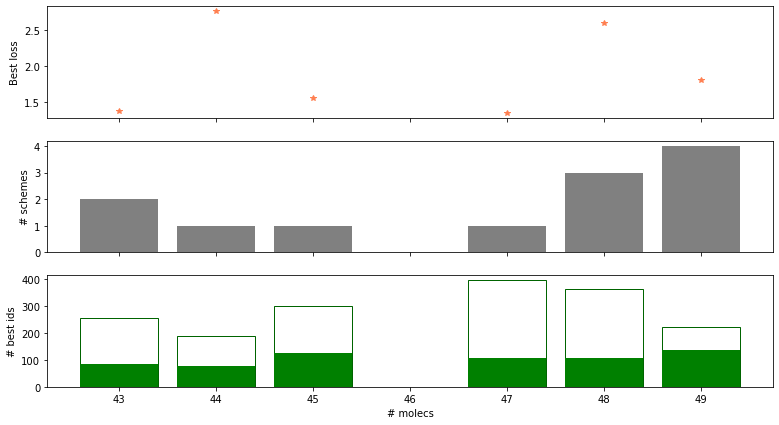

.........................................................................................................
Model losses: Min 9.181692895166258 Max: 426.48127584156646
Duration: 0:02:12.802490


New initial schemes:
number of molecs of them:  48 - 49
number of reacs of them: 116 - 140
are all imp molecs there? True
7 were created
Writing best schemes
Best losses: [0.9977848886111155, 1.3521447254843724]

.........................................................................................................
Planet         max_percent          Absolute error         Worst molec        max_percent for all molecs     ...for major species
.........................................................................................................
hd2094    0.9977848886111155    1.946016320863997e-06         ['H2', 57]         11910.898385253377 11910.898385253377
hd1897    1.3521447254843724    5.719387379143903e-06         ['H2', 43]         53972.34073533795 53972.34073533795
................

ValueError: Item wrong length 28 instead of 40555.

In [4]:
GA.run(n_iterations=n_iterations, n_write=3, save_all_schemes=save_all_schemes, max_processes=6,
       min_iteration_write=1)

In [ ]:
GA.schemes_heatmap(apply_context=True, n_pops=10, init_str=GA.params['pop_prefix'],
                   planets=GA.params['planets'], gridspec_kw={"height_ratios":[.1, .1, 1], "width_ratios": [1,.05],
                                    "wspace":0.05, "hspace":0.05}, loss_thresholds=[1, 1.5],
                                    adjust = [0.1, 0.92, 0.2, 0.85])

In [ ]:
int(str(date.today())[-1])-1

In [ ]:
GA._write_schemes()


In [ ]:
!pkill -f pac